# ACE/SWEPAM hourly data exploration

Explore the local NOAA/SWPC operational hourly product from the NASA SolarSoft archive. This is not the scientific Level 2 product; correspondence with the tournament target remains unconfirmed.

All timestamps are UTC. Cleaned columns preserve missing observations as null values. No interpolation or forward filling is performed. Historical files do not establish real-time availability.

From the project root, install and launch with:
```bash
uv sync --locked --group notebooks
uv run --group notebooks jupyter lab notebooks/01_ace_hourly_exploration.ipynb
```


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.titlesize": 13})
pd.set_option("display.max_columns", 20)

# Locate the project whether the kernel starts in the root or notebooks folder.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts/download_ace_hourly.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Start the kernel inside the BenchLab project.")
DATA_DIR = ROOT / "data/ace_hourly"
DATA_FILE = DATA_DIR / "ace_swepam_hourly.parquet"
# Set this explicitly to the partial Parquet file if incomplete data are intended.
REPORT_FILE = DATA_DIR / "download_report.json"


## Load and validate the dataset

The complete file is selected explicitly. An empty or partial download is not silently treated as a complete dataset.

In [2]:
if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}. Run the downloader first.")
df = pd.read_parquet(DATA_FILE)
required = {"timestamp_utc", "speed_km_s", "density_cm3", "temperature_k", "status", "is_valid"}
if required - set(df.columns):
    raise ValueError(f"Missing columns: {sorted(required - set(df.columns))}")
if df.empty:
    raise ValueError("The Parquet file is empty. Resolve download failures before exploring it.")
df["timestamp_utc"] = pd.to_datetime(df["timestamp_utc"], utc=True)
if df["timestamp_utc"].isna().any() or df["timestamp_utc"].duplicated().any():
    raise ValueError("Timestamps must be present and unique.")
if not df["timestamp_utc"].eq(df["timestamp_utc"].dt.floor("h")).all():
    raise ValueError("Timestamps must lie on the hourly grid.")
df = df.set_index("timestamp_utc").sort_index()
print(f"File: {DATA_FILE.relative_to(ROOT)}")
print(f"Records: {len(df):,}")
print(f"Observed range: {df.index.min()} to {df.index.max()}")
display(df.head())
display(df.dtypes.rename("Data type").to_frame())


File: data/ace_hourly/ace_swepam_hourly.parquet
Records: 8,784
Observed range: 2024-01-01 00:00:00+00:00 to 2024-12-31 23:00:00+00:00


,speed_km_s_raw,status,is_valid,speed_km_s,density_cm3_raw,density_cm3,temperature_k_raw,temperature_k,source_file
timestamp_utc,,,,,,,,,
2024-01-01 00:00:00+00:00,333.5,6,False,NaN,18.1,NaN,119000.0,NaN,202401_ace_swepam_1h.txt
2024-01-01 01:00:00+00:00,322.3,1,False,NaN,18.5,NaN,73600.0,NaN,202401_ace_swepam_1h.txt
2024-01-01 02:00:00+00:00,-9999.9,9,False,NaN,-9999.9,NaN,-100000.0,NaN,202401_ace_swepam_1h.txt
2024-01-01 03:00:00+00:00,-9999.9,9,False,NaN,-9999.9,NaN,-100000.0,NaN,202401_ace_swepam_1h.txt
2024-01-01 04:00:00+00:00,-9999.9,9,False,NaN,-9999.9,NaN,-100000.0,NaN,202401_ace_swepam_1h.txt


,Data type
speed_km_s_raw,float64
status,int8
is_valid,bool
speed_km_s,float64
density_cm3_raw,float64
density_cm3,float64
temperature_k_raw,float64
temperature_k,float64
source_file,str


## Download report and hourly coverage

A matching report extends the coverage window to the requested dates, including missing boundary hours. For a current-day request, only completed hours at report generation are evaluated. A stale or mismatched report is displayed but not used to define coverage.

,Download report
product,ACE/SWEPAM NOAA/SWPC hourly real-time (SolarSo...
start,2024-01-01
end_inclusive,2024-12-31
generated_at,2026-09-26T11:13:12.736899+00:00
rows,8784
valid_rows,6057


Failed months in report: 0
Report matches selected dataset: True


,Value
Expected completed hours,8784.000000
Present records,8784.000000
Missing records,0.000000
Present records with invalid speed,2727.000000
Valid speed hours,6057.000000
Valid speed coverage (%),68.954918


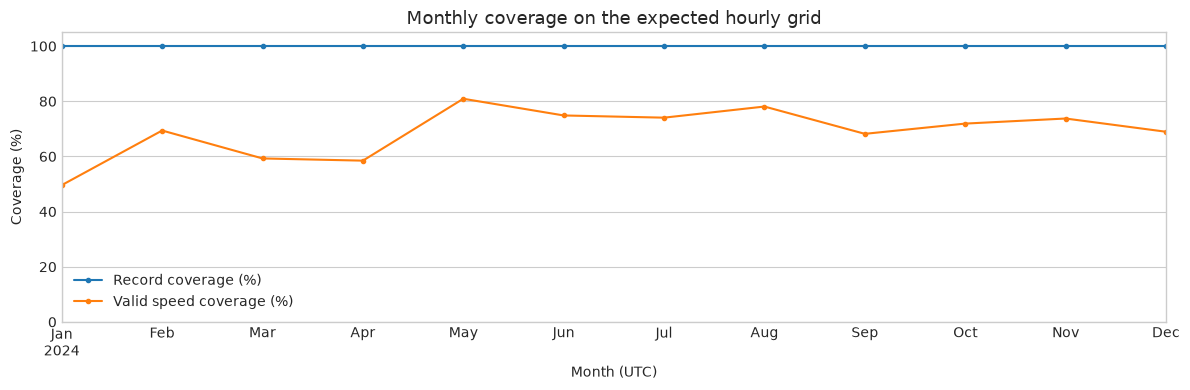

In [3]:
report = json.loads(REPORT_FILE.read_text()) if REPORT_FILE.exists() else {}
report_matches = bool(report) and (
    report.get("parquet") == DATA_FILE.name
    and report.get("rows") == len(df)
    and pd.to_datetime(report.get("first_timestamp"), utc=True) == df.index.min()
    and pd.to_datetime(report.get("last_timestamp"), utc=True) == df.index.max()
)
if report:
    display(pd.Series({k: report.get(k) for k in [
        "product", "start", "end_inclusive", "generated_at", "rows", "valid_rows"
    ]}, name="Download report").to_frame())
    print(f"Failed months in report: {len(report.get('failed_months', []))}")
print(f"Report matches selected dataset: {report_matches}")
start, end = df.index.min(), df.index.max()
if report_matches:
    start = pd.Timestamp(report["start"], tz="UTC")
    stop = min(pd.Timestamp(report["end_inclusive"], tz="UTC") + pd.Timedelta(days=1),
               pd.Timestamp(report["generated_at"]).floor("h"))
    end = stop - pd.Timedelta(hours=1)
grid = pd.date_range(start, end, freq="h", name="timestamp_utc")
hourly = df.reindex(grid)
hourly["record_present"] = grid.isin(df.index)
hourly["valid_speed"] = hourly["speed_km_s"].notna()
summary = pd.Series({
    "Expected completed hours": len(grid),
    "Present records": int(hourly["record_present"].sum()),
    "Missing records": int((~hourly["record_present"]).sum()),
    "Present records with invalid speed": int((hourly["record_present"] & ~hourly["valid_speed"]).sum()),
    "Valid speed hours": int(hourly["valid_speed"].sum()),
    "Valid speed coverage (%)": 100 * hourly["valid_speed"].mean(),
})
display(summary.rename("Value").to_frame())
monthly = hourly.resample("MS").agg(
    expected_hours=("record_present", "size"),
    present_hours=("record_present", "sum"),
    valid_speed_hours=("valid_speed", "sum"),
)
monthly["Record coverage (%)"] = 100 * monthly.present_hours / monthly.expected_hours
monthly["Valid speed coverage (%)"] = 100 * monthly.valid_speed_hours / monthly.expected_hours
monthly[["Record coverage (%)", "Valid speed coverage (%)"]].plot(marker=".")
plt.title("Monthly coverage on the expected hourly grid")
plt.xlabel("Month (UTC)")
plt.ylabel("Coverage (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()


## Quality flags and longest gaps

`is_valid` describes speed validity only. A missing record differs from a present record whose speed fails quality checks. Gap lengths below count consecutive hours without a usable speed, including both cases.

In [4]:
display(df["status"].value_counts(dropna=False).sort_index().rename("Records").to_frame())
variables = {"speed_km_s": "Solar wind speed (km/s)",
             "density_cm3": "Proton density (cm⁻³)",
             "temperature_k": "Proton temperature (K)"}
display((100 * hourly[list(variables)].isna().mean()).rename("Missing or invalid (%)").to_frame())
unavailable = ~hourly["valid_speed"]
groups = unavailable.ne(unavailable.shift()).cumsum()
gaps = (hourly.loc[unavailable].reset_index()
        .groupby(groups.loc[unavailable].to_numpy())
        .agg(start_utc=("timestamp_utc", "min"), end_utc=("timestamp_utc", "max"),
             duration_hours=("timestamp_utc", "size"))
        .sort_values("duration_hours", ascending=False))
display(gaps.head(15))


,Records
status,
0,6080
1,864
3,225
4,3
6,142
9,1470


,Missing or invalid (%)
speed_km_s,31.045082
density_cm3,30.783242
temperature_k,31.056466


,start_utc,end_utc,duration_hours
9,2024-01-01 21:00:00+00:00,2024-01-02 11:00:00+00:00,15
119,2024-01-16 21:00:00+00:00,2024-01-17 11:00:00+00:00,15
115,2024-01-15 21:00:00+00:00,2024-01-16 11:00:00+00:00,15
921,2024-04-02 22:00:00+00:00,2024-04-03 11:00:00+00:00,14
163,2024-01-21 21:00:00+00:00,2024-01-22 09:00:00+00:00,13
15,2024-01-02 21:00:00+00:00,2024-01-03 09:00:00+00:00,13
105,2024-01-13 21:00:00+00:00,2024-01-14 09:00:00+00:00,13
45,2024-01-07 21:00:00+00:00,2024-01-08 07:00:00+00:00,11
843,2024-03-26 21:00:00+00:00,2024-03-27 07:00:00+00:00,11
39,2024-01-06 21:00:00+00:00,2024-01-07 07:00:00+00:00,11


## Time series

Hourly curves retain gaps. Daily medians summarize available values only; consult coverage before interpreting changes.

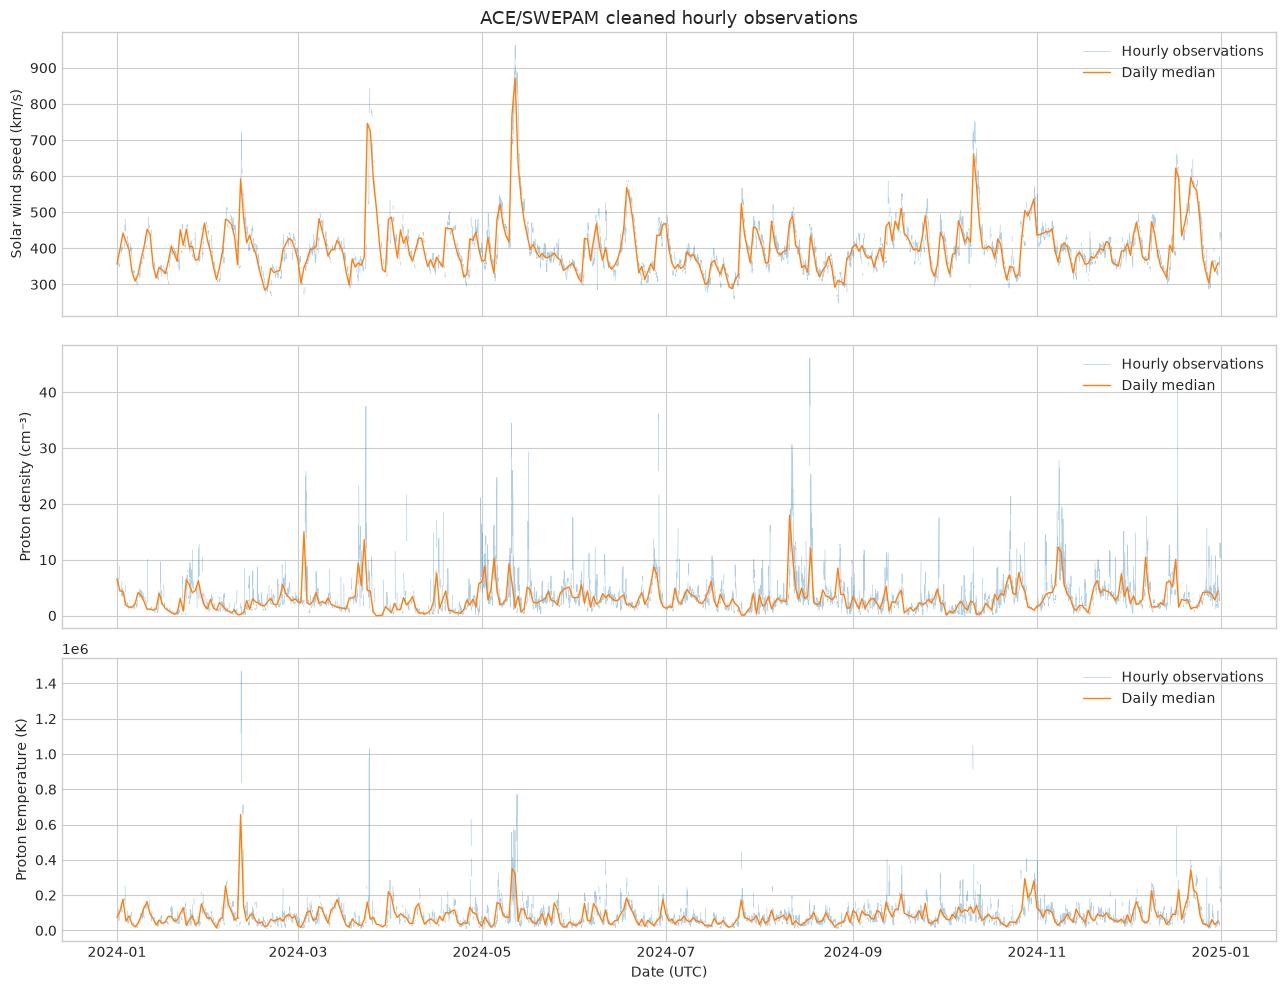

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, (column, label) in zip(axes, variables.items()):
    ax.plot(hourly.index, hourly[column], alpha=0.35, linewidth=0.5, label="Hourly observations")
    daily = hourly[column].resample("D").median()
    ax.plot(daily.index, daily, linewidth=1, label="Daily median")
    ax.set_ylabel(label)
    ax.legend(loc="upper right")
axes[0].set_title("ACE/SWEPAM cleaned hourly observations")
axes[-1].set_xlabel("Date (UTC)")
fig.tight_layout()
plt.show()


## Distributions and descriptive statistics

Only non-null cleaned observations contribute. Density and temperature also have logarithmic views to expose their dynamic range; zero values are excluded only from those views.

,count,mean,std,min,1%,5%,50%,95%,99%,max
speed_km_s,6057.0,400.210335,76.274629,249.4,287.156,311.68,387.4,526.06,720.5,962.6
density_cm3,6080.0,3.598158,3.672119,0.0,0.100,0.40,2.7,10.20,18.5,46.1
temperature_k,6056.0,84845.904888,76725.808506,11100.0,14210.000,22200.00,65550.0,199000.00,362350.0,1470000.0


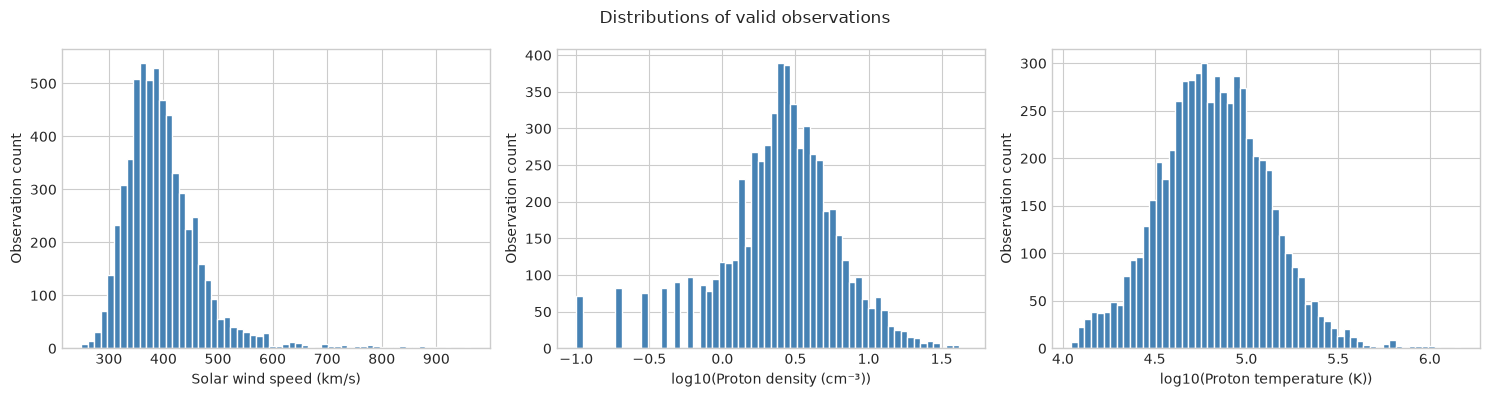

In [6]:
display(df[list(variables)].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (column, label) in zip(axes, variables.items()):
    values = df[column].dropna()
    if column != "speed_km_s":
        values = np.log10(values[values > 0])
        label = f"log10({label})"
    ax.hist(values, bins=60, color="steelblue", edgecolor="white")
    ax.set_xlabel(label)
    ax.set_ylabel("Observation count")
fig.suptitle("Distributions of valid observations")
fig.tight_layout()
plt.show()


## Relationships between variables

Pairwise correlations use available cleaned observations. Sample sizes can differ between pairs. These descriptive associations do not establish causality or forecast skill.

,Solar wind speed (km/s),Proton density (cm⁻³),Proton temperature (K)
Solar wind speed (km/s),1.000000,0.016655,0.613430
Proton density (cm⁻³),0.016655,1.000000,-0.066285
Proton temperature (K),0.613430,-0.066285,1.000000


,Solar wind speed (km/s),Proton density (cm⁻³),Proton temperature (K)
Pairwise observation counts,,,
Solar wind speed (km/s),6057,6057,6056
Proton density (cm⁻³),6057,6080,6056
Proton temperature (K),6056,6056,6056


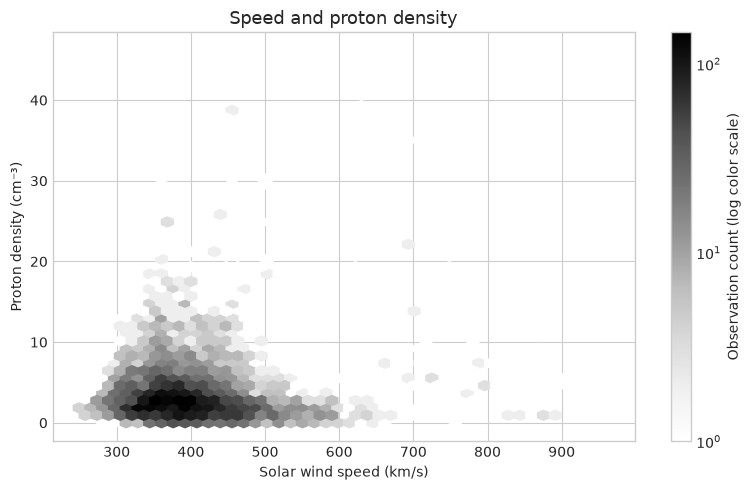

In [7]:
valid = df[list(variables)]
display(valid.corr(method="pearson").rename(index=variables, columns=variables))
presence = valid.notna().astype("int64")
display((presence.T @ presence).rename(index=variables, columns=variables)
        .rename_axis("Pairwise observation counts"))
fig, ax = plt.subplots(figsize=(8, 5))
pair = valid[["speed_km_s", "density_cm3"]].dropna()
if len(pair):
    artist = ax.hexbin(pair.speed_km_s, pair.density_cm3, gridsize=45, mincnt=1, bins="log")
    fig.colorbar(artist, ax=ax, label="Observation count (log color scale)")
ax.set(xlabel=variables["speed_km_s"], ylabel=variables["density_cm3"],
       title="Speed and proton density")
fig.tight_layout()
plt.show()


## Lag correlations

Correlations are computed on the regular hourly grid without filling gaps. Each lag uses only valid pairs. The 27-day lag is a recurrence hypothesis to investigate, not evidence of out-of-sample forecast performance.

,Valid pairs,Pearson correlation
Lag (hours),,
1,4343,0.987116
6,4918,0.911393
12,4777,0.814307
24,5003,0.646640
48,4974,0.342822
72,4923,0.155414
168,4827,-0.044696
648,4509,0.044179


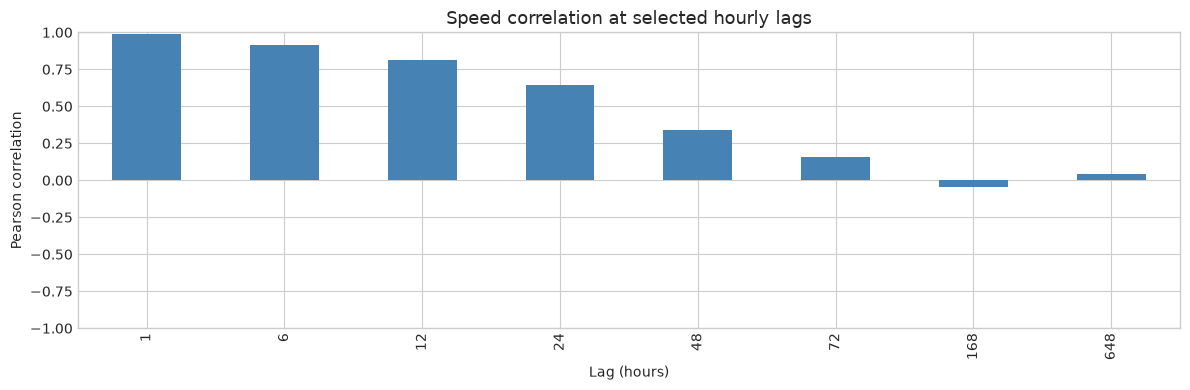

In [8]:
speed = hourly["speed_km_s"]
lag_rows = []
for lag in [1, 6, 12, 24, 48, 72, 7 * 24, 27 * 24]:
    pairs = pd.concat([speed.rename("current"), speed.shift(lag).rename("lagged")], axis=1).dropna()
    correlation = (pairs.current.corr(pairs.lagged)
                   if len(pairs) > 2 and pairs.nunique().min() > 1 else np.nan)
    lag_rows.append({"Lag (hours)": lag, "Valid pairs": len(pairs), "Pearson correlation": correlation})
lag_summary = pd.DataFrame(lag_rows).set_index("Lag (hours)")
display(lag_summary)
lag_summary["Pearson correlation"].plot.bar(color="steelblue")
plt.title("Speed correlation at selected hourly lags")
plt.ylabel("Pearson correlation")
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()


## Interpretation checklist

- Distinguish absent timestamps from invalid measurements before choosing modeling windows.
- Inspect long gaps and monthly coverage before interpreting seasonal changes.
- Keep raw values and quality flags for traceability; do not use sentinel values as physical measurements.
- Evaluate persistence and recurrence with chronological backtests before claiming predictive skill.
- Fit preprocessing on training periods only and document assumptions about source latency.
